In [47]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [48]:
import sys
sys.path.append("../src")

In [49]:
import pandas as pd
import numpy as np
import networkx as nx

In [50]:
DATA_ROOT_DIR = "../data/icefase/data"

In [51]:
metadata = pd.read_csv(f"{DATA_ROOT_DIR}/experiment_metadata.csv")
metadata

,Experiment id,Fate map id,Sample size,Sampling scheme
0,1,1,100,fixed
1,2,2,100,fixed
2,3,3,100,fixed
3,4,4,100,fixed
4,5,5,100,fixed
...,...,...,...,...
3305,3306,327,100,proportional
3306,3307,328,100,proportional
3307,3308,329,100,proportional
3308,3309,330,100,proportional


In [85]:
id = 1670
eid = metadata.loc[id, "Experiment id"]
fatemap_id = metadata.loc[id, "Fate map id"]

print("id:\t\t", id)
print("experiment id:\t", eid)
print("fatemap id:\t", fatemap_id)


id:		 1670
experiment id:	 1671
fatemap id:	 16


In [86]:
import json

def get_fatemap(fatemap_id):

    with open(f"{DATA_ROOT_DIR}/fatemaps/fate_map{fatemap_id:04d}.json") as f:
        diff_T = nx.DiGraph()

        fatemap = json.load(f)

        all_nodes = fatemap["all_id"]
        for node in all_nodes:
            diff_T.add_node(node)
        
        merges = fatemap["merge"]
        for root, children in merges.items():
            for child in children:
                diff_T.add_edge(root, child)
        
        diff_times = fatemap["diff_time"]
        for node, time in diff_times.items():
            if time == "Inf": 
                diff_T.nodes[node]["diff_time"] = None
            else:
                diff_T.nodes[node]["diff_time"] = time
        
        diff_T.graph['root'] = fatemap["root_id"]
        
        transition_probs = pd.DataFrame(np.zeros((len(all_nodes), len(all_nodes))), index=all_nodes, columns=all_nodes)
        diff_mode_probs = fatemap["diff_mode_probs"]

        for root, children in merges.items():
            qs = diff_mode_probs[root]
            for children, q in zip(children, qs):
                transition_probs.loc[root, children] = q

    return diff_T, transition_probs

diff_T, transition_probs = get_fatemap(fatemap_id)

In [87]:
from plotters import plot_differentiation_tree

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


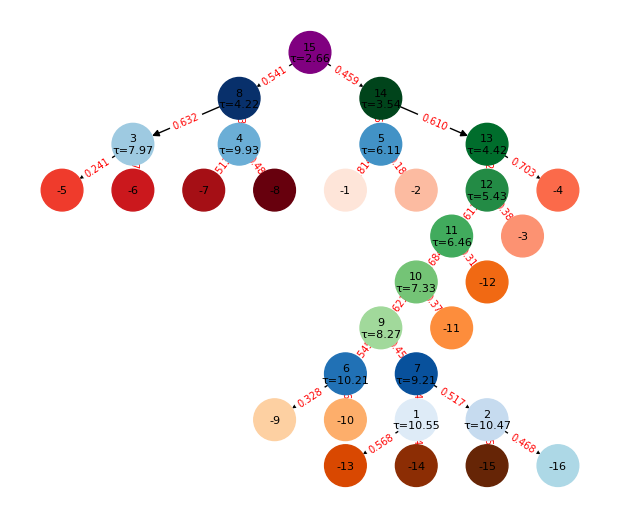

In [88]:
plot_differentiation_tree(diff_T, transition_probabilities=transition_probs)

In [89]:
import networkx as nx
from newick import read

tree = read(f"{DATA_ROOT_DIR}/simulated_phylogeny/{eid:04d}.newick")[0]

import networkx as nx
import re

def tree_to_nx(tree):
    G = nx.DiGraph()

    def node_name(n):
        return n.name if n.name else str(id(n))
    
    # parse cell_type from node name
    def parse_cell_type(name):
        # assumes format: type_<cell_type>_gen_...
        m = re.match(r"type_(-?\d+)_gen_(-?\d+)_(-?\d+)", name)
        if m:
            return str(m.group(1))
        else:
            return None

    root_name = node_name(tree)
    G.graph["root"] = root_name   # store root

    def add_node(node):
        parent = node_name(node)
        G.add_node(parent, state=parse_cell_type(parent))

        for child in node.descendants:
            child_name = node_name(child)

            G.add_edge(
                parent,
                child_name,
                weight=child.length,
            )

            add_node(child)

    add_node(tree)
    return G

T = tree_to_nx(tree)

In [90]:
T.nodes(data=True)

NodeDataView({'type_15_gen_0_1': {'state': '15'}, 'type_15_gen_1_1': {'state': '15'}, 'type_15_gen_2_1': {'state': '15'}, 'type_15_gen_3_1': {'state': '15'}, 'type_14_gen_-1_1': {'state': '14'}, 'type_13_gen_-1_1': {'state': '13'}, 'type_13_gen_0_1': {'state': '13'}, 'type_11_gen_-1_1': {'state': '11'}, 'type_-11_gen_9_1': {'state': '-11'}, 'type_-11_gen_9_2': {'state': '-11'}, 'type_-4_gen_0_1': {'state': '-4'}, 'type_-4_gen_6_9': {'state': '-4'}, 'type_-4_gen_16_187': {'state': '-4'}, 'type_-4_gen_16_188': {'state': '-4'}, 'type_-4_gen_16_8': {'state': '-4'}, 'type_-4_gen_-1_1': {'state': '-4'}, 'type_-4_gen_0_5': {'state': '-4'}, 'type_-4_gen_5_11': {'state': '-4'}, 'type_-4_gen_16_161': {'state': '-4'}, 'type_-4_gen_16_162': {'state': '-4'}, 'type_-4_gen_1_25': {'state': '-4'}, 'type_-4_gen_5_32': {'state': '-4'}, 'type_-4_gen_16_163': {'state': '-4'}, 'type_-4_gen_16_164': {'state': '-4'}, 'type_-4_gen_2_59': {'state': '-4'}, 'type_-4_gen_5_84': {'state': '-4'}, 'type_-4_gen_16_17

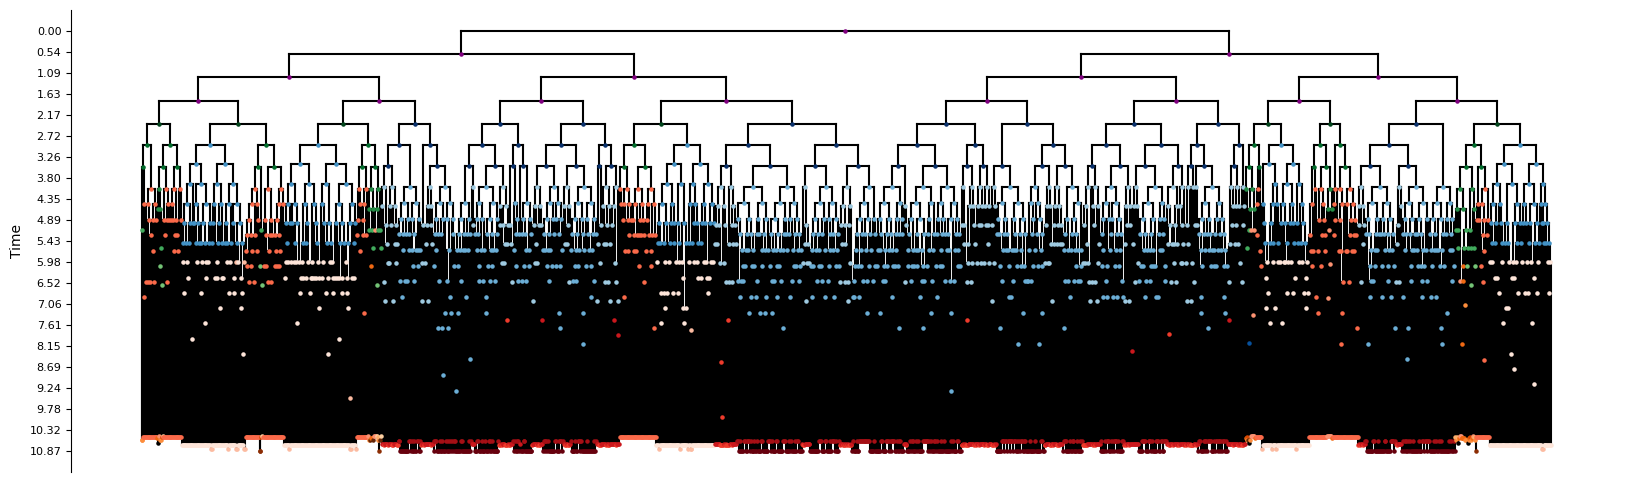

In [91]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph["root"], add_labels=False, figsize=(20, 6))

In [92]:
from likelihood import add_node_times

In [93]:
T = add_node_times(T, T.graph['root'], reverse=False)

In [94]:
diff_times = {}

for node in nx.dfs_postorder_nodes(diff_T, source=diff_T.graph['root']):
    if node[0] != "-": # internal node
        diff_time = 0

        children_states = list(diff_T.successors(node))

        nodes_with_children_state = [n for n, d in T.nodes(data=True) if d.get("state") in children_states]
        their_parent_nodes = list(set([list(T.predecessors(n))[0] for n in nodes_with_children_state]))
        
        for pnode in their_parent_nodes:
            children_nodes = list(T.successors(pnode))
            children_node_states = [T.nodes[child].get("state") for child in children_nodes]

            if len(set(children_node_states) & set(children_states)) > 1:
                diff_time = max(diff_time, T.nodes[pnode]['T'])

        diff_times[node] = diff_time


In [95]:
diff_times

{'5': 5.4781489727,
 '6': 0,
 '1': 0,
 '2': 8.0690834243,
 '7': 0,
 '9': 0,
 '10': 0,
 '11': 5.6072086426,
 '12': 4.6088616631,
 '13': 3.5129533653,
 '14': 2.4,
 '3': 6.9871807708,
 '4': 9.3078521445,
 '8': 3.4990147719999998,
 '15': 1.7999999999999998}

In [96]:
EPS = 1e-9

for node in nx.dfs_preorder_nodes(diff_T, source=diff_T.graph['root']):
    if node[0] != "-":
        children_states = list(diff_T.successors(node))
        for child_state in children_states:
            if child_state[0] != "-":
                diff_times[child_state] = max(diff_times[child_state], diff_times[node]) + EPS

In [97]:
diff_times

{'5': 5.4781489737,
 '6': 5.6072086466,
 '1': 5.6072086476,
 '2': 8.0690834253,
 '7': 5.6072086466,
 '9': 5.6072086456,
 '10': 5.6072086446,
 '11': 5.6072086436,
 '12': 4.6088616641,
 '13': 3.5129533663,
 '14': 2.400000001,
 '3': 6.9871807718,
 '4': 9.3078521455,
 '8': 3.499014773,
 '15': 1.7999999999999998}

In [98]:
corrected_diff_T = diff_T.copy()

EPS = 1e-9

for state, diff_time in diff_times.items():
    # corrected_diff_T.nodes[state]['diff_time'] = diff_time + EPS
    corrected_diff_T.nodes[state]['diff_time'] = (diff_time + EPS) / 11.5

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


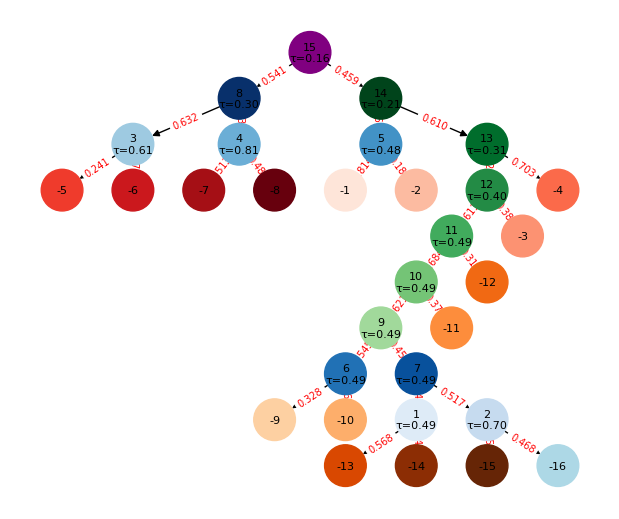

In [99]:
plot_differentiation_tree(corrected_diff_T, transition_probabilities=transition_probs)

In [100]:
def pull_down_diff_times(diff_T, stretch=0.2):
    # expects diff times to be within (0, 1)
    diff_T = diff_T.copy()
    for n in nx.dfs_postorder_nodes(diff_T, source=diff_T.graph['root']):
        if not n.startswith("-"):
            children = list(diff_T.successors(n))
            children_diff_times = []
            for c in children:
                if c.startswith("-"): children_diff_times.append(1)
                else: children_diff_times.append(diff_T.nodes[c]['diff_time'])
            
            node_diff_time = diff_T.nodes[n]['diff_time']
            min_children_diff_time = min(children_diff_times)
            pulled_down_diff_time = node_diff_time + (min_children_diff_time - node_diff_time) * stretch
            print(n, children, children_diff_times, min_children_diff_time, node_diff_time, pulled_down_diff_time)
            diff_T.nodes[n]['diff_time'] = pulled_down_diff_time
    
    return diff_T

corrected_diff_T = pull_down_diff_times(corrected_diff_T, stretch=1/3)

5 ['-1', '-2'] [1, 1] 1 0.4763607804086956 0.6509071869391304
6 ['-9', '-10'] [1, 1] 1 0.4875833606608696 0.6583889071072464
1 ['-13', '-14'] [1, 1] 1 0.4875833607478261 0.6583889071652174
2 ['-15', '-16'] [1, 1] 1 0.7016594283739132 0.8011062855826088
7 ['1', '2'] [0.6583889071652174, 0.8011062855826088] 0.6583889071652174 0.4875833606608696 0.5445185428289855
9 ['6', '7'] [0.6583889071072464, 0.5445185428289855] 0.5445185428289855 0.48758336057391305 0.5065617546589372
10 ['9', '-11'] [0.5065617546589372, 1] 0.5065617546589372 0.48758336048695655 0.49390949187761674
11 ['10', '-12'] [0.49390949187761674, 1] 0.49390949187761674 0.4875833604 0.4896920708925389
12 ['-3', '11'] [1, 0.4896920708925389] 0.4896920708925389 0.40077057957391304 0.4304110766801217
13 ['12', '-4'] [0.4304110766801217, 1] 0.4304110766801217 0.30547420585217394 0.34711982946148984
14 ['5', '13'] [0.6509071869391304, 0.34711982946148984] 0.34711982946148984 0.20869565234782608 0.25483704471904733
3 ['-5', '-6'] [1

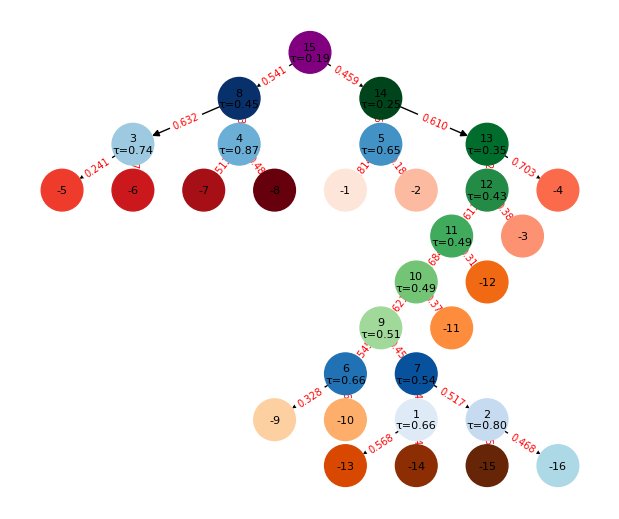

In [101]:
plot_differentiation_tree(corrected_diff_T, transition_probabilities=transition_probs)

In [102]:
rev_T = T.copy()
for n in T.nodes():
    rev_T.nodes[n]['T'] = (T.nodes[n]['T']) / 11.5

for u, v, data in rev_T.edges(data=True):
    data['weight'] /= 11.5    

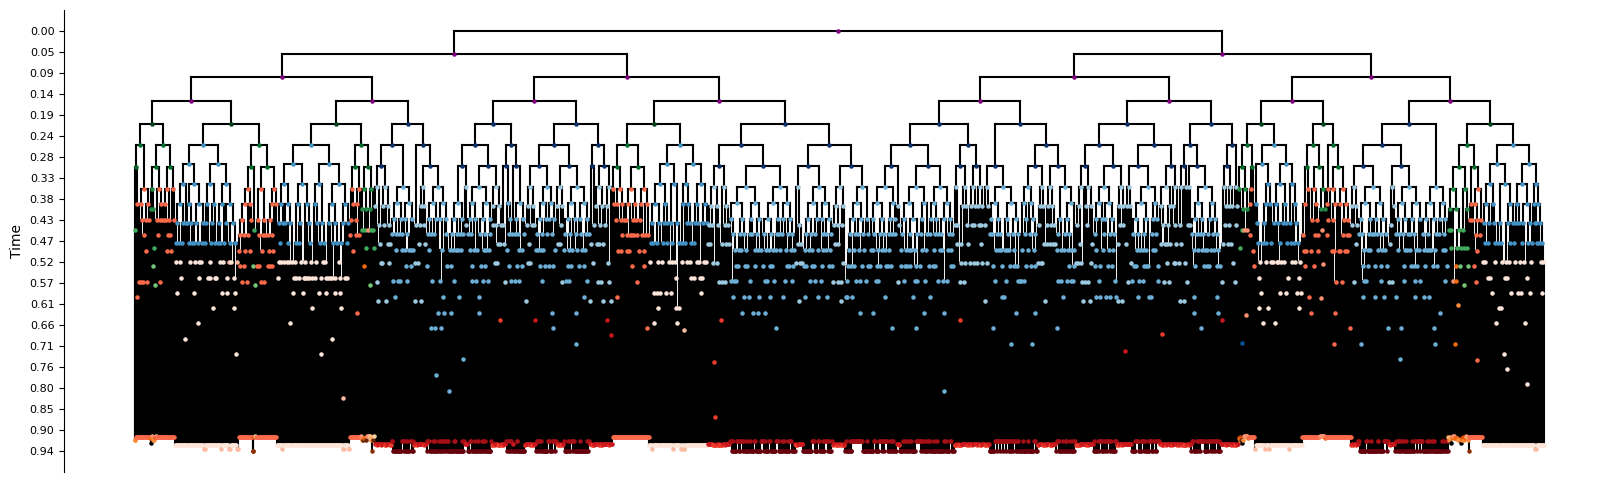

In [103]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(rev_T, root=rev_T.graph["root"], add_labels=False, figsize=(20, 6))

In [104]:
rev_T2 = rev_T.copy()

for n in rev_T.nodes():
    rev_T2.nodes[n]['T'] = (1 - rev_T.nodes[n]['T'])

In [105]:
rev_diff_T = corrected_diff_T.copy()
for n in corrected_diff_T.nodes():
    diff_time = rev_diff_T.nodes[n].get('diff_time')
    if diff_time is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = (1 - rev_diff_T.nodes[n]['diff_time'])

In [106]:
from likelihood import assign_states_to_internal_nodes

rev_T2 = assign_states_to_internal_nodes(rev_T2, corrected_diff_T, correct=True)

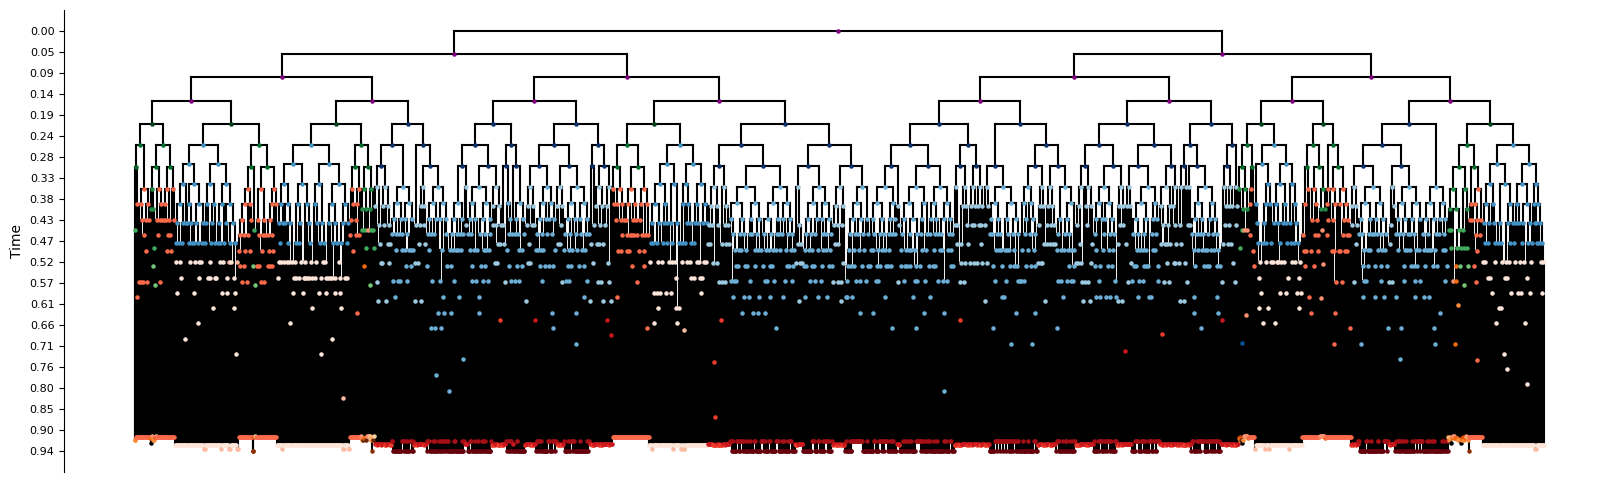

In [107]:
draw_ultrametric_tree(rev_T2, root=rev_T2.graph["root"], add_labels=False, figsize=(20, 6))

In [108]:
types = list(diff_T.nodes())

transition_maps = [
    (i, succ)
    for i in diff_T.nodes()
    if (succ := list(diff_T.successors(i)))
]

print(types)
print(transition_maps)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '-1', '-2', '-3', '-4', '-5', '-6', '-7', '-8', '-9', '-10', '-11', '-12', '-13', '-14', '-15', '-16']
[('1', ['-13', '-14']), ('2', ['-15', '-16']), ('3', ['-5', '-6']), ('4', ['-7', '-8']), ('5', ['-1', '-2']), ('6', ['-9', '-10']), ('7', ['1', '2']), ('8', ['3', '4']), ('9', ['6', '7']), ('10', ['9', '-11']), ('11', ['10', '-12']), ('12', ['-3', '11']), ('13', ['12', '-4']), ('14', ['5', '13']), ('15', ['14', '8'])]


In [109]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize


def calculate_log_likelihood_of_transitions(transition_probabilities, cell_lineage_T, diff_T):
    ll = 0.0

    for u, v in cell_lineage_T.edges():
        u_state = cell_lineage_T.nodes[u]['state']
        v_state = cell_lineage_T.nodes[v]['state']

        path = nx.shortest_path(diff_T, u_state, v_state)

        for i in range(len(path) - 1):
            prob = transition_probabilities.loc[path[i], path[i+1]]
            ll += np.log(prob)

    return ll


def unpack_params(theta):

    k = 0

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)

        # stable softmax
        logits -= np.max(logits)
        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return Q


def neg_log_likelihood(theta, trees, diff_T):

    Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:
        log_p = calculate_log_likelihood_of_transitions(Q, cell_lineage_T, diff_T)

        if not np.isfinite(log_p):
            return 1e10

        total_nll += -log_p

    return total_nll


def pack_initial():

    params = []

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T),   # FIX: must be a tuple
        method="L-BFGS-B"
    )

    print(result)

    Q = unpack_params(result.x)

    return Q

In [110]:
trees = [rev_T2]

In [111]:
# Q = find_params(trees, corrected_diff_T)

In [112]:
# Q

In [113]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

def plot_transition_scatter(diff_T, transition_probs, Q):

    gt_vals = []
    pred_vals = []

    for u, v in diff_T.edges():
        u_state = u
        v_state = v

        # if not v.startswith("-"):
        if True:

            gt = transition_probs.loc[u_state, v_state]
            pred = Q.loc[u_state, v_state]

            gt_vals.append(gt)
            pred_vals.append(pred)

    # compute spearman correlation
    rho, pval = spearmanr(gt_vals, pred_vals)

    print("Spearman rho:", rho)
    print("p-value:", pval)

    # scatter plot
    plt.figure(figsize=(5,5))
    plt.scatter(gt_vals, pred_vals)
    plt.xlabel("Ground truth transition probability")
    plt.ylabel("Predicted transition probability")
    plt.title(f"Transition Probabilities (Spearman ρ = {rho:.3f})")
    plt.plot([0,1], [0,1])  # reference diagonal
    plt.tight_layout()
    plt.show()

    return rho

In [114]:
# rho = plot_transition_scatter(diff_T, transition_probs, Q)

In [115]:
def find_params_simple(trees, diff_T):

    state_to_idx = {state: i for i, state in enumerate(types)}
    
    q = np.zeros((len(types), len(types)))

    for cell_lineage_T in trees:

        for u, v in cell_lineage_T.edges():
            u_state = cell_lineage_T.nodes[u]['state']
            v_state = cell_lineage_T.nodes[v]['state']

            path = nx.shortest_path(diff_T, u_state, v_state)

            for i in range(len(path) - 1):
                u_idx = state_to_idx[path[i]]
                v_idx = state_to_idx[path[i+1]]
                q[u_idx, v_idx] += 1

    # Normalize row-wise (handle zero rows safely)
    row_sums = q.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1  # avoid division by zero

    q_normalized = q / row_sums

    Q = pd.DataFrame(q_normalized, index=types, columns=types)
    
    return Q

In [116]:
Q = find_params_simple(trees, corrected_diff_T)
Q

,1,2,3,4,5,6,7,8,9,10,...,-7,-8,-9,-10,-11,-12,-13,-14,-15,-16
1,0.0,0.0,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.0,0.0,0.000000,0.00000,0.5,0.5,0.0,0.0
2,0.0,0.0,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.5,0.5
3,0.0,0.0,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.38209,0.61791,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.0
5,0.0,0.0,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.0
6,0.0,0.0,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.5,0.5,0.000000,0.00000,0.0,0.0,0.0,0.0
7,0.5,0.5,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.0
8,0.0,0.0,0.625,0.375,0.000000,0.000000,0.000000,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.0
9,0.0,0.0,0.000,0.000,0.000000,0.347826,0.652174,0.0000,0.000000,0.00000,...,0.00000,0.00000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.0
10,0.0,0.0,0.000,0.000,0.000000,0.000000,0.000000,0.0000,0.621622,0.00000,...,0.00000,0.00000,0.0,0.0,0.378378,0.00000,0.0,0.0,0.0,0.0


Spearman rho: 0.8037635760075479
p-value: 8.854514011909183e-08


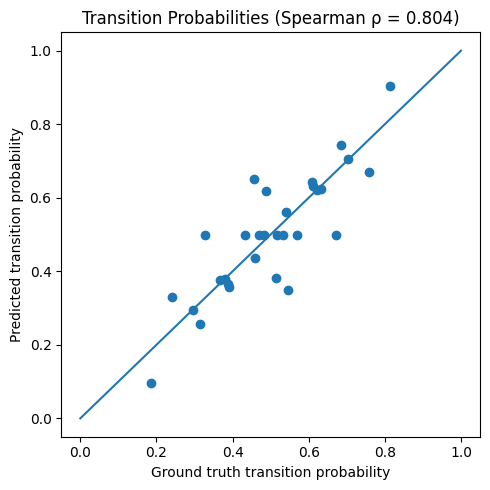

In [117]:
rho = plot_transition_scatter(diff_T, transition_probs, Q)

## Plot scatter for mutliple trees

Spearman rho: 0.7363877223672006
p-value: 0.0


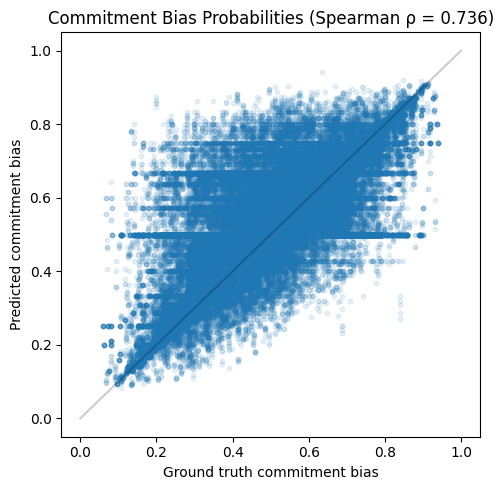

np.float64(0.7363877223672006)

In [127]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import os

def plot_transition_scatter_for_many():

    gt_vals = []
    pred_vals = []

    def plot_transition_scatter(id):

        eid = metadata.loc[id, "Experiment id"]
        fatemap_id = metadata.loc[id, "Fate map id"]
        sampling_scheme = metadata.loc[id, "Sampling scheme"]

        # if sampling_scheme == "fixed": return

        q_file_path = f"../outputs/icefase/commitment_bias_predictions_50/{eid}/q.csv"

        if not os.path.exists(q_file_path): return

        diff_T, transition_probs = get_fatemap(fatemap_id)

        Q = pd.read_csv(q_file_path, index_col=0)
        Q.index = Q.index.astype(str)
        Q.columns = Q.columns.astype(str)

        # print(Q)

        for u, v in diff_T.edges():
            u_state = u
            v_state = v

            if not v.startswith("-"):
            # if True:

                gt = transition_probs.loc[u_state, v_state]
                pred = Q.loc[u_state, v_state]

                gt_vals.append(gt)
                pred_vals.append(pred)
    
    for i in range(3310):
        plot_transition_scatter(i)

    # compute spearman correlation
    rho, pval = spearmanr(gt_vals, pred_vals)
    print("Spearman rho:", rho)
    print("p-value:", pval)

    # scatter plot
    plt.figure(figsize=(5,5))
    plt.scatter(gt_vals, pred_vals, s=10, alpha=0.1)
    plt.xlabel("Ground truth commitment bias")
    plt.ylabel("Predicted commitment bias")
    plt.title(f"Commitment Bias Probabilities (Spearman ρ = {rho:.3f})")
    plt.plot([0,1], [0,1], color='black', alpha=0.2)
    plt.tight_layout()
    plt.show()
    
    return rho

plot_transition_scatter_for_many()